# 04d – Synthèse des données socio-économiques

Je réunis les 3 fichiers propres (04a CSP, 04b unités urbaines, 04c Ameli) et je les montre sur des cartes pour voir où se trouvent les différences entre départements.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 1. Réunir les 3 fichiers

On réunit les tableaux grâce à la colonne code_dep.

In [2]:
#Lire les 3 fichiers de synthèse de 04a/b/c (Data processed)
csp = pd.read_csv('../data/processed/insee_csp_2022_propre.csv', dtype={'code_dep': str})
uu = pd.read_csv('../data/processed/insee_urbain_2017_propre.csv', dtype={'code_dep': str})
ameli = pd.read_csv('../data/processed/ameli_2024_propre.csv', dtype={'code_dep': str})

# merge réunit 2 tableaux à la fois
# on='code_dep': on rassemble les lignes avec le même code de département

#on rassemble les données ameli avec les données de pourcentage urbain (pct_urbain) de uu
socio = pd.merge(ameli, uu[['code_dep', 'pct_urbain']], on='code_dep')

# On enlève nom_dep et est_drom, déjà présents dans socio et on garde le reste des données csp
socio = pd.merge(socio, csp.drop(columns=['nom_dep', 'est_drom']), on='code_dep')

print(socio.shape)
socio.head()

(100, 25)


,code_dep,nom_dep,est_drom,population,nb_generalistes,nb_pediatres,nb_pneumologues,nb_allergologues,nb_kines,nb_sos,...,sos_present,pct_urbain,pct_agriculteurs,pct_artisans,pct_cadres,pct_prof_inter,pct_employes,pct_ouvriers,pct_retraites,pct_sans_activite
0,01,Ain,False,688626,368,9,7,2,533,0,...,False,67.0,0.6,4.1,10.0,16.6,15.5,14.2,26.0,12.9
1,02,Aisne,False,518817,311,9,16,4,294,1,...,True,53.2,1.0,2.7,4.8,12.4,16.0,16.5,30.0,16.6
2,03,Allier,False,332599,221,5,5,1,351,0,...,False,58.3,1.6,3.3,4.9,11.3,15.2,13.0,37.6,13.2
3,04,Alpes-Hte-Provence,False,169806,152,10,1,1,241,1,...,True,61.9,1.5,5.4,6.6,13.3,14.4,10.5,34.9,13.5
4,05,Hautes-Alpes,False,142006,178,0,0,0,383,0,...,False,59.5,1.6,5.4,5.9,15.2,16.2,9.9,34.6,11.2


On obtient 100 départements (Mayotte n'est pas dans le fichier CSP) et 25 colonnes d'informations pour chacun.

## 2. Cartes

Nécessite la bibliothèque geopandas pour dessiner la carte. Le fond de carte est obtenu grâce à geojson (lien)

(96, 3)
  code                      nom  \
0   01                      Ain   
1   02                    Aisne   
2   03                   Allier   
3   04  Alpes-de-Haute-Provence   
4   05             Hautes-Alpes   

                                            geometry  
0  POLYGON ((4.78021 46.17668, 4.79458 46.21832, ...  
1  POLYGON ((4.04797 49.40564, 4.03991 49.3974, 4...  
2  POLYGON ((3.03207 46.79491, 3.04907 46.75808, ...  
3  POLYGON ((5.67604 44.19143, 5.69209 44.18648, ...  
4  POLYGON ((6.26057 45.12685, 6.29922 45.10855, ...  
  code_dep                      nom             nom_dep
0       01                      Ain                 Ain
1       02                    Aisne               Aisne
2       03                   Allier              Allier
3       04  Alpes-de-Haute-Provence  Alpes-Hte-Provence
4       05             Hautes-Alpes        Hautes-Alpes
5       06          Alpes-Maritimes     Alpes-Maritimes
6       07                  Ardèche             Ardèche
7  

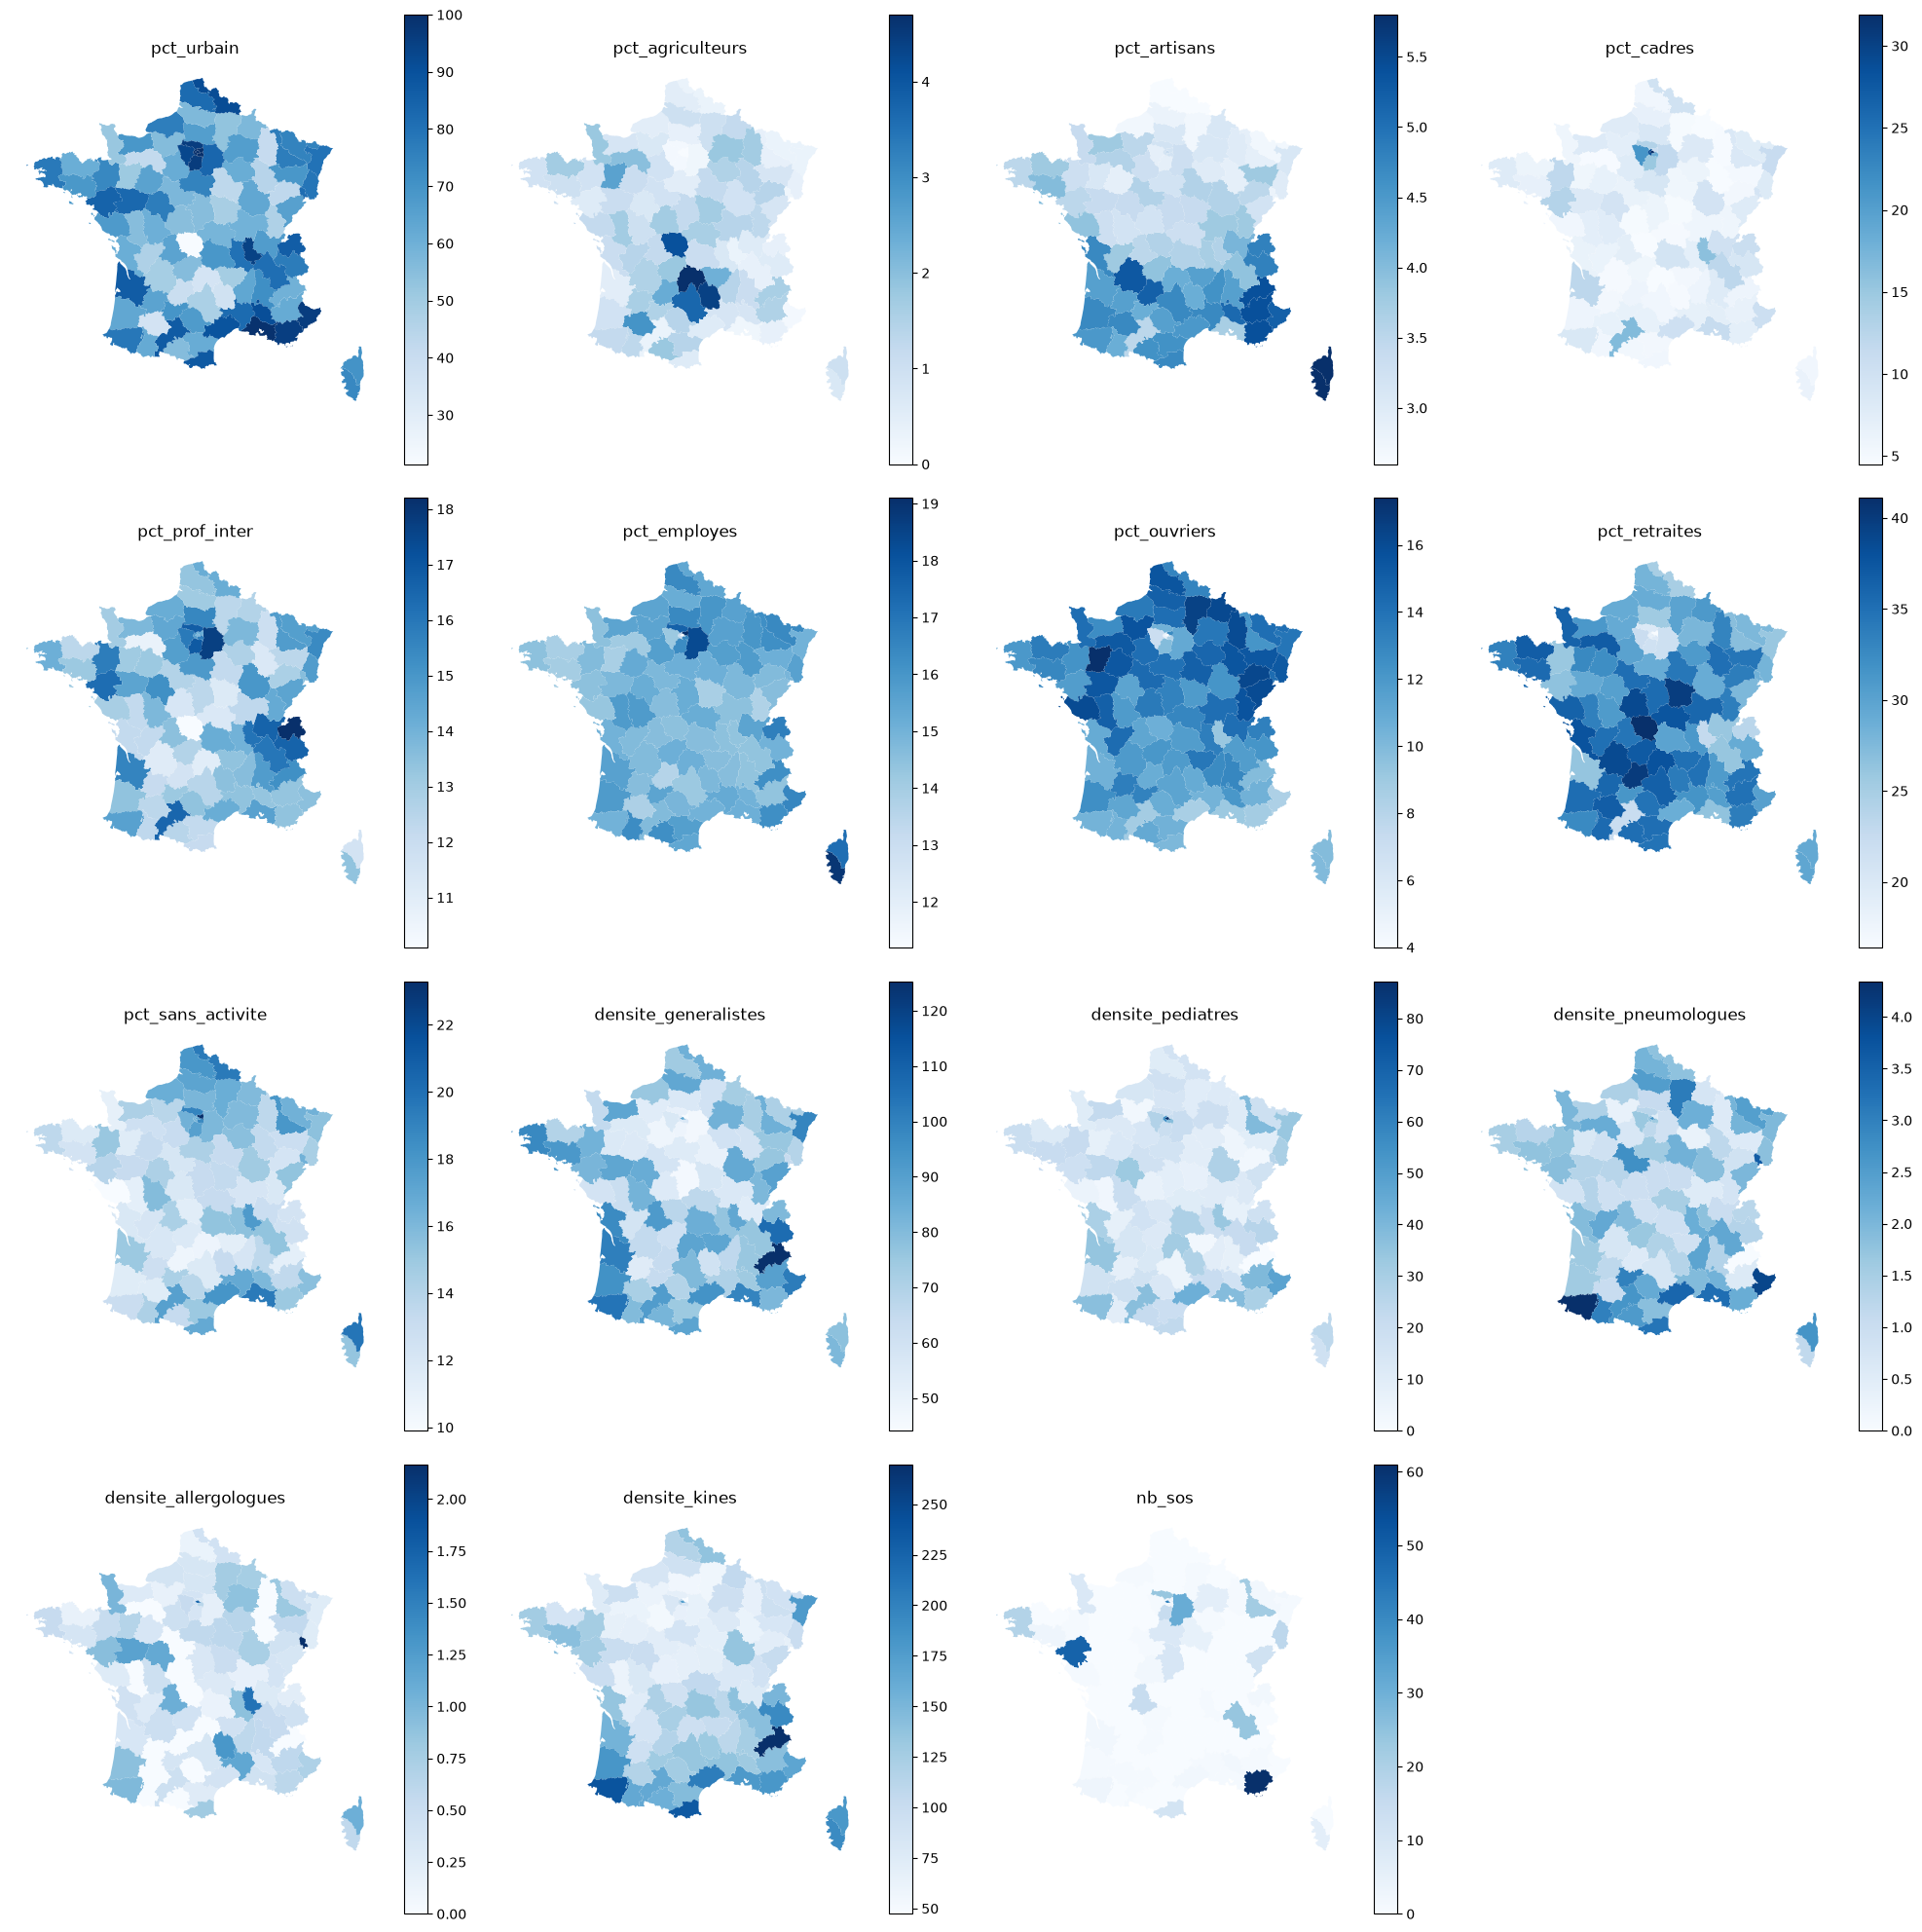

In [3]:
#  adresse internet du fond de carte (contours des 96 départements)
lien = 'https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson'
carte = gpd.read_file(lien)


# contrôle : taille et premières lignes du fichier de carte
print(carte.shape)
print(carte.head())

# renommer 'code' en 'code_dep', pour avoir le même nom que dans socio
carte = carte.rename(columns={'code': 'code_dep'})
#coller nos donées (socio) au contour des départements (carte)
carte = pd.merge(carte, socio, on='code_dep')

# contrôle : nom (carte) et nom_dep (Ameli) = même département
print(carte[['code_dep', 'nom', 'nom_dep']].head(10))

variables = ['pct_urbain', 'pct_agriculteurs', 'pct_artisans', 'pct_cadres',
             'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites',
             'pct_sans_activite', 'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
             'densite_allergologues', 'densite_kines', 'nb_sos']

plt.figure(figsize=(20, 20))
for i in range(15):
    ax = plt.subplot(4, 4, i + 1)
    carte.plot(column=variables[i], cmap='Blues', legend=True, ax=ax)
    ax.set_title(variables[i])
    ax.axis('off')
plt.tight_layout()
plt.show()


Unités : les colonnes pct_ sont des pourcentages (pct_urbain = % des habitants vivant en ville, les autres = % des 15 ans ou plus). Les colonnes densite_ sont pour 100 000 habitants (pour 100 000 enfants de 0 à 19 ans pour les pédiatres). nb_sos est un nombre de médecins.Les cartes montrent les 96 départements de métropole. Les DROM ne sont pas dessinés mais restent dans le tableau socio (Mayotte n'y est pas car elle manque dans le fichier CSP).

**Conclusion** 
Ce qui ressort des cartes :

- Une opposition ville / campagne : les départements urbains sont en Île-de-France, dans le Nord, autour de Lyon et sur la côte méditerranéenne. Le centre est rural, avec plus de retraités et d'agriculteurs.

- Le nord et l'est ont plus d'ouvriers et de personnes sans activité.

- Les cadres sont presque uniquement en Île-de-France.

- Le sud a plus d'artisans et commerçants, et aussi plus de soignants : généralistes, kinés et pneumologues

- Les pédiatres et les allergologues sont rares : les cartes sont presque uniformes, seules quelques grandes villes ressortent.

- Pour SOS Médecins, seuls quelques départements ressortent. Mais attention le chiffre est incomplet.


## 3. Enregistrement

In [4]:
socio.to_csv('../data/processed/socio_eco_dep.csv', index=False)

## Conclusion

Le fichier socio_eco_dep.csv a une ligne par département. Il pourra être réuni avec les données santé du groupe grâce au code département.

À voir avec le groupe : les années ne sont pas les mêmes (2017, 2022, 2024), et on garde ou non les DROM.